<a href="https://colab.research.google.com/github/tustus1022-ui/esaa/blob/main/ESAA_OB_WEEK12_transcription1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<딥러닝 파이토치 교과서> 7장 p.417-440를 필사

## **7.6 게이트 순환 신경망(GRU)**
**GRU(Gated Recurrent Unit)**: 게이트 메커니즘이 적용된 RNN 프레임워크의 한 종류이면서 **LSTM보다 구조가 간단함**

### **7.6.1 GRU 구조**
GRU는 LSTM의 **망각 게이트와 입력 게이트를 하나로 합친 것**이며, 별도의 **업데이트 게이트**로 구성됨
* **하나의 게이트 컨트롤러(gate controller)**가 망각 게이트와 입력 게이트를 모두 제어함
  * 게이트 컨트롤러가 **1**을 출력하면 망각 게이트는 열리고 입력 게이트는 닫힘
  * **0**을 출력하면 망각 게이트는 닫히고 입력 게이트는 열림
  * 즉, 이전 기억이 저장될 때마다 단계별 입력은 삭제됨
* GRU는 **출력 게이트가 없어서** 전체 상태 벡터가 매 단계마다 출력됨. 이전 상태의 어느 부분을 출력할지 제어하는 새로운 게이트 컨트롤러가 따로 존재함

**망각 게이트(reset gate)**
* 과거 정보를 적당히 **초기화(reset)**하려는 목적으로, 시그모이드 함수를 출력으로 이용해 (0, 1) 값을 이전 은닉층에 곱함
* 이전 시점의 은닉층 값에 현시점 정보에 대한 가중치를 곱한 것
* 수식: r_t = σ(W_r · [h_{t-1}, x_t])

**업데이트 게이트(update gate)**
* 과거와 현재 정보의 **최신화 비율**을 결정하는 역할
* 시그모이드로 출력된 결과(z_t)는 **현시점의 정보량**을 결정하고, 1에서 뺀 값(1 - z_t)은 직전 시점의 은닉층 정보와 곱함
* 수식: z_t = σ(W_z · [h_{t-1}, x_t])

**후보군(candidate)**
* 현시점의 정보에 대한 후보군을 계산함
* 과거 은닉층의 정보를 그대로 쓰지 않고 **망각 게이트의 결과를 이용**해 후보군을 계산함
* 수식: ĥ_t = tanh(W · [r_t * h_{t-1}, x_t])
  * *는 **점 단위 연산(pointwise operation)**. 예) 벡터를 더할 때 각 차원(dimension)에 맞게 곱하거나 더할 수 있음

**은닉층 계산**
* **업데이트 게이트 결과와 후보군 결과를 결합**해 현시점의 은닉층을 계산함
* 시그모이드 함수의 결과는 현시점 결과에 대한 정보량을, 1 - 시그모이드 함수의 결과는 과거의 정보량을 결정함
* 수식: h_t = (1 - z_t) * h_{t-1} + z_t × ĥ_t

### **7.6.2 GRU 셀 구현**
GRU 셀을 파이토치로 구현함. 데이터셋(**MNIST**)과 대부분의 코드는 LSTM 셀과 같으므로 **네트워크의 차이점 위주**로 학습하면 좋음

In [22]:
# 라이브러리 호출
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dataset
from torch.autograd import Variable
from torch.nn import Parameter
from torch import Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader
import math

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
cuda = True if torch.cuda.is_available() else False

Tensor = torch.cuda.FloatTensor if cuda else torch.FloatTensor

torch.manual_seed(125)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(125)

**데이터 전처리**
* 데이터셋을 평균과 표준편차를 기준으로 **정규화**하고 텐서로 변경함

In [23]:
# 데이터 전처리
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (1.0,))
])

In [24]:
# 데이터셋 내려받기 및 전처리 적용
from torchvision.datasets import MNIST
download_root = '../chap07/MNIST_DATASET'

train_dataset = MNIST(download_root, transform=mnist_transform, train=True,
                      download=True)
valid_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                      download=True)
test_dataset = MNIST(download_root, transform=mnist_transform, train=False,
                     download=True)

* 데이터로더로 전처리된 데이터셋을 메모리로 불러옴. 단, 메모리로 불러오는 시점은 **train_loader, valid_loader, test_loader가 호출되는 시점**임
* 일반적으로 **검증과 테스트용 데이터셋은 섞지(shuffle) 않음**. 예제에서는 다양한 학습을 위해 True로 지정함

In [25]:
# 데이터셋 메모리로 가져오기
batch_size = 64
train_loader = DataLoader(dataset= train_dataset,
                          batch_size=batch_size,
                          shuffle=True)
valid_loader = DataLoader(dataset= valid_dataset,
                          batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(dataset= test_dataset,
                         batch_size=batch_size,
                         shuffle=False)

In [26]:
# 변수 값 설정
batch_size = 100
n_iters = 6000
num_epochs = n_iters / (len(train_dataset) / batch_size)
num_epochs = int(num_epochs)

**GRU 셀 네트워크**
* **3 × hidden_size를 쓰는 이유**: LSTM 셀은 4를 곱했지만 GRU 셀은 **세 개의 게이트**를 사용하므로 3을 곱함
  * 엄밀히 게이트는 두 개(망각, 입력 게이트)지만, 탄젠트 활성화 함수가 적용되는 부분을 **'새로운 게이트(newgate)'**로 정의해서 총 3을 곱함
* LSTM 셀은 gates를 x2h + h2h로 한 번에 정의했지만, GRU 셀은 **gate_x와 gate_h로 개별적인 상태를 유지**함
* gate_x와 gate_h를 각각 chunk(3, 1)로 **세 개로 쪼갬**(망각, 입력, 새로운 게이트용)
* 망각(reset)·입력 게이트 → **시그모이드**, 새로운 게이트 → **tanh**

In [27]:
# GPU 셀 네트워크
class GRUCell(nn.Module):
    def __init__(self, input_size, hidden_size, bias=True):
        super(GRUCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.bias = bias
        self.x2h = nn.Linear(input_size, 3 * hidden_size, bias=bias)
        self.h2h = nn.Linear(hidden_size, 3 * hidden_size, bias=bias)
        self.reset_parameters()

    def reset_parameters(self):  # 파라미터를 초기화
        std = 1.0 / math.sqrt(self.hidden_size)
        for w in self.parameters():
            w.data.uniform_(-std, std)

    def forward(self, x, hidden):
        x = x.view(-1, x.size(1))

        gate_x = self.x2h(x)  # LSTM 셀에서는 gates를 x2h+h2h로 정의했지만
                              # GRU 셀에서는 개별적이 상태를 유지합니다.
        gate_h = self.h2h(hidden)

        gate_x = gate_x.squeeze()
        gate_h = gate_h.squeeze()

        i_r, i_i, i_n = gate_x.chunk(3, 1) # 총 세 개의 게이트(망각, 입력, 새로운 게이트)를 위해
                                           # 세 개로 쪼갭니다.
        h_r, h_i, h_n = gate_h.chunk(3, 1)

        resetgate = F.sigmoid(i_r + h_r)
        inputgate = F.sigmoid(i_i + h_i)
        newgate = F.tanh(i_n + (resetgate * h_n)) # '새로운 게이트'는 탄젠트 활성화 함수가
                                                  # 적용된 게이트

        hy = newgate +inputgate * (hidden - newgate)
        return hy

**전반적인 네트워크**
* 앞에서 정의한 GRUCell을 불러와서 사용함
* LSTM 셀은 셀 상태도 정의했지만, **GRU 셀은 셀 상태를 사용하지 않음** → 은닉 상태(h0)만 0으로 초기화함
* 시퀀스 길이만큼 GRU 셀을 반복 적용하고, 마지막 출력을 완전연결층에 통과시킴

In [28]:
# 전반적인 네트워크 구조
class GRUModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, bias=True):
      super(GRUModel, self).__init__()
      self.hidden_dim = hidden_dim
      self.layer_dim = layer_dim

      self.gru_cell = GRUCell(input_dim, hidden_dim, layer_dim) # 앞에서 정의한 GRUCell 함수를 불러옵니다.
      self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
      if torch.cuda.is_available():
        h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
      else:
        h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

      outs = []
      hn = h0[0,:,:] # LSTM 셀에서는 셀 상태에 대해서도 정의했었지만 GRU 셀에서는 셀은 사용되지 않습니다.

      for seq in range(x.size(1)):
        hn = self.gru_cell(x[:,seq,:], hn)
        outs.append(hn)
        out = outs[-1].squeeze()
        out = self.fc(out)
        return out

**학습 및 성능 검증**
* 변수: input_dim 28, hidden_dim 128, layer_dim 1, output_dim 10
* 손실 함수: **CrossEntropyLoss** / 옵티마이저: **SGD**(학습률 0.1)

In [29]:
# 옵티마이저와 손실 함수 설정
input_dim = 28
hidden_dim = 128
layer_dim = 1
output_dim = 10

model = GRUModel(input_dim, hidden_dim, layer_dim, output_dim)

if torch.cuda.is_available():
  model.cuda()

criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [30]:
# 모델 학습 및 성능 검증
seq_dim = 28
loss_list = []
iter = 0
for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    if torch.cuda.is_available():
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = Variable(labels.cuda())
    else:
      images = Variable(images.view(-1, seq_dim, input_dim))
      labels = Variable(labels)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)

    if torch.cuda.is_available():
      loss.cuda()

    loss.backward()
    optimizer.step()

    loss_list.append(loss.item())
    iter += 1

    if iter % 500 == 0:
      correct = 0
      total = 0
      for images, labels in valid_loader:
        if torch.cuda.is_available():
          images = Variable(images.view(-1, seq_dim, input_dim).cuda())
        else:
          images = Variable(images.view(-1, seq_dim, input_dim))

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)

        if torch.cuda.is_available():
          correct += (predicted.cpu() == labels.cpu()).sum()
        else:
          correct += (predicted == labels).sum()

      accuracy = 100 * correct / total
      print('Iteration: {}. Loss: {}. Accuracy: {}'.format(iter, loss.item(), accuracy))

Iteration: 500. Loss: 2.3020687103271484. Accuracy: 10.319999694824219
Iteration: 1000. Loss: 2.31019926071167. Accuracy: 11.350000381469727
Iteration: 1500. Loss: 2.306100845336914. Accuracy: 11.350000381469727
Iteration: 2000. Loss: 2.300555944442749. Accuracy: 11.350000381469727
Iteration: 2500. Loss: 2.2927584648132324. Accuracy: 11.350000381469727
Iteration: 3000. Loss: 2.309049367904663. Accuracy: 11.350000381469727
Iteration: 3500. Loss: 2.3057708740234375. Accuracy: 11.350000381469727
Iteration: 4000. Loss: 2.304710865020752. Accuracy: 11.350000381469727
Iteration: 4500. Loss: 2.307932138442993. Accuracy: 11.350000381469727
Iteration: 5000. Loss: 2.2947356700897217. Accuracy: 11.350000381469727
Iteration: 5500. Loss: 2.2989978790283203. Accuracy: 11.350000381469727
Iteration: 6000. Loss: 2.3024721145629883. Accuracy: 11.350000381469727
Iteration: 6500. Loss: 2.3102259635925293. Accuracy: 11.350000381469727
Iteration: 7000. Loss: 2.3134260177612305. Accuracy: 11.350000381469727


* 결과: 검증 정확도 약 **98%** → LSTM 셀과 비슷함 (p.426)
* 시계열 처리 모델(RNN, LSTM, GRU) 중 **어떤 것이 더 좋다고 말할 수 없음**
  → 주어진 데이터셋을 **다양한 모델에 적용해 최적의 모델을 찾는 것**이 중요함

In [33]:
# 테스트 데이터셋을 이용한 모델 예측
def evaluate(model, val_iter):
  corrects, total, total_loss = 0, 0, 0
  model.eval()
  for images, labels in val_iter:
    if torch.cuda.is_available():
      images = Variable(images.view(-1, seq_dim, input_dim).cuda())
      labels = Variable(labels.cuda())
    else:
      images = Variable(images.view(-1, seq_dim, input_dim)).to(device)
      labels = Variable(labels).to(device)

    logit = model(images).to(device)
    loss = F.cross_entropy(logit, labels, reduction="sum")
    _, predicted = torch.max(logit.data, 1)
    total += labels.size(0)
    total_loss += loss.item()
    corrects += (predicted == labels).sum()

  avg_loss = total_loss / len(val_iter.dataset)
  avg_accuracy = corrects / total
  return avg_loss, avg_accuracy

In [34]:
# 모델 예측 결과
test_loss, test_acc = evaluate(model, test_loader)
print("Test Loss: %5.2f | Test Accuracy: %5.2f" % (test_loss, test_acc))

Test Loss:  2.30 | Test Accuracy:  0.11


* 테스트 결과: **Test Accuracy 0.98** → LSTM 셀을 사용했을 때와 성능이 비슷함
* MNIST에서는 성능이 높지만 다른 데이터셋에서는 정확도가 낮게 나올 수 있음
  → 주어진 데이터셋에 **다양한 모델을 적용해 보고 최적의 하이퍼파라미터를 찾는 것**이 중요함

### **7.6.3 GRU 계층 구현**
LSTM 계층에서 사용한 데이터셋(**스타벅스 주가**)과 코드와 비슷하므로 **모델의 네트워크 위주**로 학습함

In [35]:
# 라이브러리 호출
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [36]:
### 추가 ###
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 28.80 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


In [37]:
# 데이터셋 불러오기
data = pd.read_csv('/content/080289//chap07/data/SBUX.csv')
print(data.dtypes)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


**데이터 전처리**
* 'Date' 칼럼을 **인덱스**로 지정하고, 'Volume' 칼럼의 데이터 형식을 **실수(float)**로 변경함
* 참고: **대·소문자를 구분**하기 때문에 'Date'를 'date'로 쓰면 오류가 발생함

In [38]:
# 인덱스 설정 및 데이터 타입 변경
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
data['Volume'] = data['Volume'].astype(float)

* 마지막 칼럼을 제외한 모든 칼럼은 X(훈련용), 마지막 칼럼(**Volume**)은 레이블(y)로 지정함

In [39]:
# 훈련과 레이블 데이터셋 분리
X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]
print(X)
print(y)

                  Open        High         Low       Close   Adj Close
Date                                                                  
2019-12-11   86.260002   86.870003   85.849998   86.589996   84.145752
2019-12-12   88.000000   88.889999   87.540001   88.209999   85.720032
2019-12-13   88.019997   88.790001   87.580002   88.669998   86.167046
2019-12-16   89.139999   89.300003   88.430000   88.779999   86.273941
2019-12-17   88.870003   88.970001   87.470001   88.129997   85.642288
...                ...         ...         ...         ...         ...
2020-12-04  101.349998  102.940002  101.070000  102.279999  101.442787
2020-12-07  102.010002  102.220001  100.690002  101.410004  100.579918
2020-12-08  100.370003  101.570000  100.010002  101.209999  100.381554
2020-12-09  101.940002  102.209999  100.099998  100.400002   99.578186
2020-12-10  103.510002  106.089996  102.750000  105.389999  104.527336

[253 rows x 5 columns]
                Volume
Date                  
2019-12

* 훈련과 레이블 데이터셋을 **정규화**해서 분포를 조정함(X는 StandardScaler, y는 MinMaxScaler)
* 앞의 200개는 훈련, 나머지 53개는 테스트

In [40]:
# 훈련과 테스트 데이터셋 정규화
ms = MinMaxScaler()
ss = StandardScaler()

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]

y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

print("Training Shape", X_train.shape, y_train.shape)
print("Testing Shape", X_test.shape, y_test.shape)

Training Shape (200, 5) (200, 1)
Testing Shape (53, 5) (53, 1)


* 데이터셋을 네트워크에 적용하기 위해 형태를 (200, 5) → **(200, 1, 5)**로 변경함

In [41]:
# 데이터셋 형태 변경
X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                   1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                  1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


**GRU 모델의 네트워크**
* **LSTM 계층과의 차이점** 위주로 학습하는 것이 중요함
* 구성: **nn.GRU 계층**(batch_first=True) → 완전연결층(128) → 출력층, 중간에 ReLU 적용
* LSTM 계층은 셀 상태가 있었지만 **GRU는 셀 상태를 정의하지 않음** → 은닉 상태(h_0)만 0으로 초기화함

In [42]:
# GPU 모델의 네트워크
class GRU(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(GRU, self).__init__()
    self.num_classes = num_classes
    self.num_layers = num_layers
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.seq_length = seq_length

    self.gru = nn.GRU(input_size=input_size, hidden_size=hidden_size,
                      num_layers=num_layers, batch_first=True)
    self.fc_1 = nn.Linear(hidden_size, 128)
    self.fc = nn.Linear(128, num_classes)
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers, x.size(0), self.hidden_size))
    output, (hn) = self.gru(x, h_0)
    hn = hn.view(-1, self.hidden_size)
    out = self.relu(hn)
    out = self.fc_1(out)
    out = self.relu(out)
    out = self.fc(out)
    return out

* 변수: 에포크 1000, 학습률 0.0001, input_size 5, hidden_size 2, num_layers 1(GRU 계층 개수), num_classes 1
* 손실 함수: **MSELoss** / 옵티마이저: **Adam**

In [43]:
num_epochs = 1000
learning_rate = 0.0001

input_size = 5
hidden_size = 2
num_layers = 1 # GRU 계층의 개수

num_classes = 1
model = GRU(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [44]:
# 모델 학습
for epoch in range(num_epochs):
  outputs = model.forward(X_train_tensors_f)
  optimizer.zero_grad()
  loss = criterion(outputs, y_train_tensors)
  loss.backward()

  optimizer.step()
  if epoch % 100 == 0:
    print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.11692
Epoch: 100, loss: 0.04124
Epoch: 200, loss: 0.03291
Epoch: 300, loss: 0.03008
Epoch: 400, loss: 0.02830
Epoch: 500, loss: 0.02701
Epoch: 600, loss: 0.02590
Epoch: 700, loss: 0.02486
Epoch: 800, loss: 0.02385
Epoch: 900, loss: 0.02284


In [45]:
# 그래프 출력을 위한 전처리
df_x_ss = ss.transform(data.iloc[:, :-1])
df_y_ms = ms.transform(data.iloc[:, -1:])

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

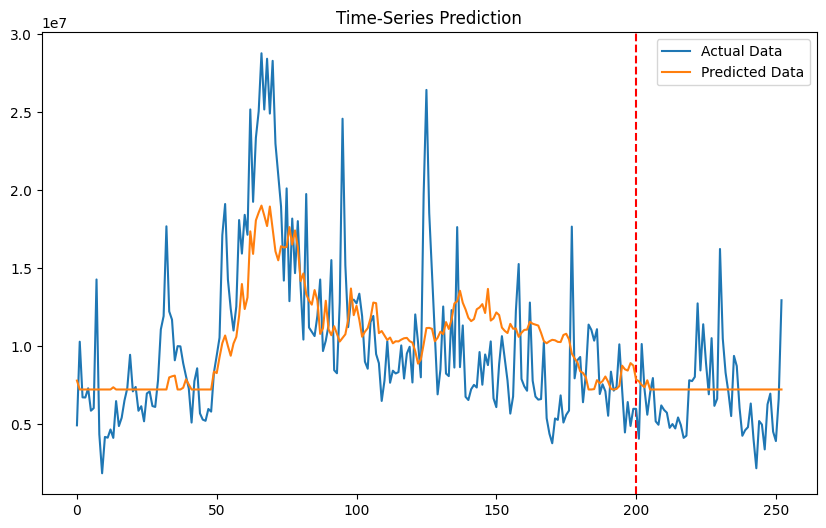

In [46]:
# 모델 예측 결과 출력
train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()

label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

* 결과: 그래프상으로는 **GRU 계층이 LSTM 계층보다 예측력이 더 좋아 보임**. 하지만 수치상 예측 정확도는 비슷했음
* 훈련 데이터를 섞어서(shuffle) 가져오도록 했기 때문에 결과는 책과 다를 수 있음

## **7.7 양방향 RNN**
RNN은 이전 시점의 데이터를 참고해서 정답을 예측하지만, 실제 문제에서는 **미래 시점의 데이터에 힌트가 있는 경우**도 많음
→ 이전 시점의 데이터뿐 아니라 **이후 시점의 데이터도 함께 활용**해 출력값을 예측하려는 것이 **양방향 RNN(bidirectional RNN)**

### **7.7.1 양방향 RNN 구조**
양방향 RNN은 하나의 출력값을 예측하는 데 **메모리 셀 두 개**를 사용함
* 첫 번째 메모리 셀: **이전 시점의 은닉 상태(forward states)**를 전달받아 현재의 은닉 상태를 계산함
* 두 번째 메모리 셀: **다음 시점의 은닉 상태(backward states)**를 전달받아 현재의 은닉 상태를 계산함
* 이 두 값을 **모두 출력층에서 출력값을 예측하는 데 사용**함
* 양방향 개념은 RNN뿐 아니라 **LSTM, GRU에도 적용**됨 → 예제는 양방향 LSTM으로 구현함

### **7.7.2 양방향 LSTM 구현**
스타벅스 주가 데이터셋을 계속 사용함. 코드도 LSTM 계층과 같으므로 **LSTM 계층과 양방향 LSTM이 어떻게 다른지 네트워크 위주로** 살펴봄
* 모델 네트워크 이전까지의 코드는 LSTM 계층과 같아서 한 번에 작성함

In [47]:
# 모델을 생성하고 학습
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.autograd import Variable
from tqdm import tqdm_notebook
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

data = pd.read_csv('/content/080289//chap07/data/SBUX.csv')
print(data.dtypes)

data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
data['Volume'] = data['Volume'].astype(float)

X = data.iloc[:, :-1]
y = data.iloc[:, 5:6]

ms = MinMaxScaler()
ss = StandardScaler()

X_ss = ss.fit_transform(X)
y_ms = ms.fit_transform(y)

X_train = X_ss[:200, :]
X_test = X_ss[200:, :]
y_train = y_ms[:200, :]
y_test = y_ms[200:, :]

X_train_tensors = Variable(torch.Tensor(X_train))
X_test_tensors = Variable(torch.Tensor(X_test))

y_train_tensors = Variable(torch.Tensor(y_train))
y_test_tensors = Variable(torch.Tensor(y_test))

X_train_tensors_f = torch.reshape(X_train_tensors, (X_train_tensors.shape[0],
                                                   1, X_train_tensors.shape[1]))
X_test_tensors_f = torch.reshape(X_test_tensors, (X_test_tensors.shape[0],
                                                  1, X_test_tensors.shape[1]))

print("Training Shape", X_train_tensors_f.shape, y_train_tensors.shape)
print("Testing Shape", X_test_tensors_f.shape, y_test_tensors.shape)

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object
Training Shape torch.Size([200, 1, 5]) torch.Size([200, 1])
Testing Shape torch.Size([53, 1, 5]) torch.Size([53, 1])


**양방향 LSTM 네트워크**
* nn.LSTM에 **bidirectional=True** 옵션을 사용하면 양방향 LSTM이 됨 → **옵션 변경만으로** 손쉽게 구현할 수 있음
  * 이 옵션은 **양방향 RNN, 양방향 GRU에도 모두** 해당됨
* 입력 데이터가 **전방향과 역방향 학습에 모두 전달**되고, 그 결과도 모두 출력에 반영됨
  * 한 번 학습하는 데 **두 개의 계층**이 필요하기 때문에 LSTM과 달리 **은닉 상태와 셀 상태에 2를 곱하고**, **마지막 출력층(hidden_size*2)에도 2를 곱해야** 함
  * num_layers = 1로 정의했지만 마치 두 개의 계층을 쓰는 것과 같아서 2를 곱함
* 출력층에는 **마지막 시간(time step상 마지막 단계)의 은닉 상태**(out[:, -1, :])를 사용함

In [48]:
# 모델의 네트워크
class biLSTM(nn.Module):
  def __init__(self, num_classes, input_size, hidden_size, num_layers, seq_length):
    super(biLSTM, self).__init__()
    self.num_classes = num_classes
    self.num_layers = num_layers
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.seq_length = seq_length

    self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                        num_layers=num_layers, bidirectional=True, batch_first=True)
    self.fc = nn.Linear(hidden_size*2, num_classes)
    self.relu = nn.ReLU()

  def forward(self, x):
    h_0 = Variable(torch.zeros(self.num_layers*2, x.size(0), self.hidden_size))
    c_0 = Variable(torch.zeros(self.num_layers*2, x.size(0), self.hidden_size))
    out, _ = self.lstm(x, (h_0, c_0))
    out = self.fc(out[:, -1, :])
    out = self.relu(out)
    return out

In [49]:
# 모델 학습
num_epochs = 1000
learning_rate = 0.0001

input_size = 5
hidden_size = 2
num_layers = 1
num_classes = 1
model = biLSTM(num_classes, input_size, hidden_size, num_layers, X_train_tensors_f.shape[1])

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

for epoch in range(num_epochs):
  outputs = model.forward(X_train_tensors_f)
  optimizer.zero_grad()

  loss = criterion(outputs, y_train_tensors)
  loss.backward()
  optimizer.step()
  if epoch % 100 == 0:
    print("Epoch: %d, loss: %1.5f" % (epoch, loss.item()))

Epoch: 0, loss: 0.04069
Epoch: 100, loss: 0.03687
Epoch: 200, loss: 0.03386
Epoch: 300, loss: 0.03143
Epoch: 400, loss: 0.02948
Epoch: 500, loss: 0.02797
Epoch: 600, loss: 0.02681
Epoch: 700, loss: 0.02592
Epoch: 800, loss: 0.02522
Epoch: 900, loss: 0.02466


* 학습 결과: loss 0.13408 → 0.02978로 감소. 오차가 줄어 훈련이 잘된 것 같지만 어느 정도인지 알기 어려움 → **그래프로 예측력 확인**

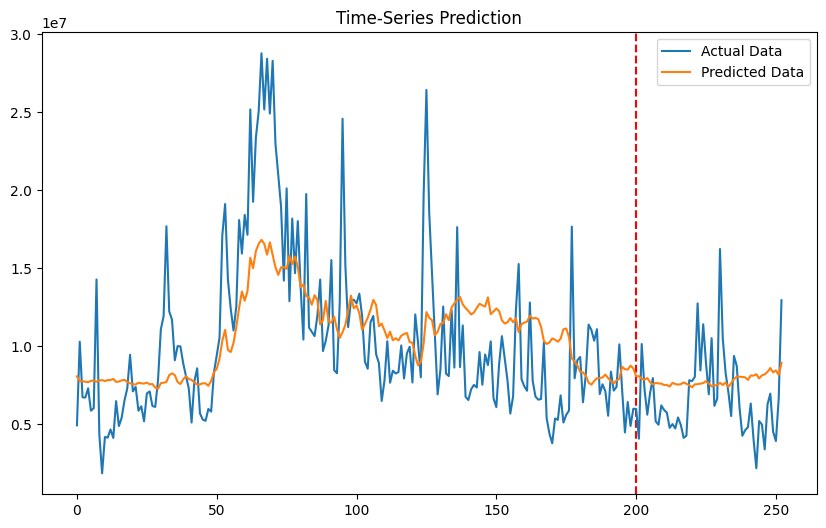

In [50]:
# 모델 평가
df_x_ss = ss.transform(data.iloc[:, :-1])
df_y_ms = ms.transform(data.iloc[:, -1:])

df_x_ss = Variable(torch.Tensor(df_x_ss))
df_y_ms = Variable(torch.Tensor(df_y_ms))
df_x_ss = torch.reshape(df_x_ss, (df_x_ss.shape[0], 1, df_x_ss.shape[1]))

train_predict = model(df_x_ss)
predicted = train_predict.data.numpy()
label_y = df_y_ms.data.numpy()

predicted = ms.inverse_transform(predicted)
label_y = ms.inverse_transform(label_y)
plt.figure(figsize=(10, 6))
plt.axvline(x=200, c='r', linestyle='--')

plt.plot(label_y, label='Actual Data')
plt.plot(predicted, label='Predicted Data')
plt.title('Time-Series Prediction')
plt.legend()
plt.show()

* 결과: 실제 레이블(파란색)과 예측 결과(주황색)가 **유사해서 예측력이 좋다고 할 수 있음** → **LSTM보다 예측 결과가 좋다**고 볼 수 있음
* 데이터가 랜덤으로 섞이기 때문에 실행할 때마다 결과가 다를 수 있고, 다른 유형의 데이터를 쓰면 결과도 달라질 수 있음

**7장 정리**
* 시계열 모델을 구현하는 것 자체는 어렵지 않음. 문제는 **데이터 처리**임
* 시계열 데이터는 대부분 단순한 숫자의 나열보다는 **사람의 언어(자연어, 한글·영문)**로 된 데이터이기 때문
* 따라서 시계열 구현에서 **가장 중요한 것은 데이터 전처리**임 → '10장 자연어 처리를 위한 임베딩'에서 자세히 다룸